# Autoencoder on the T = 48 benign + GridSybil windows (unsupervised)

A small 1D-conv autoencoder (`task/autoencoder/`) learns to compress a window of received messages into 16 numbers
(z) and rebuild it. It is trained on **all** train windows, benign and GridSybil alike, **without labels**: every
window is treated as normal. Validation = 10% of the train sender vehicles (seed 0), used only for early stopping and
the LR schedule. Labels are read only in section 5, after every test window has its reconstruction error.

This notebook runs from the repo root, imports the package classes and reads the run folder written by
`npm run ae48:train`. Sections: 1 input, 2 model, 3 training record, 4 reconstruction, 5 test, 6 analysis.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/summary.json`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder.config import AutoencoderConfig
from task.autoencoder.data import WindowDataset, vehicle_split
from task.autoencoder.model import ConvAutoencoder, count_params
from task.autoencoder.trainer import Trainer

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_fscore_support, roc_auc_score

settings = AutoencoderConfig()
runs = sorted(Path(settings.runs_dir).glob("*/summary.json"), key=lambda p: p.stat().st_mtime)
assert runs, "no finished run: npm run ae48:train"
RUN = runs[-1].parent
FEATURES = json.loads((Path(settings.data_dir) / "metadata.json").read_text())["features"]
print("run folder:", RUN)

run folder: task/autoencoder/runs/seed0


## 1. Input

Each window is the messages one receiver heard from one sender pseudonym, cut to at most 48 messages (1 Hz) with
13 normalised features per message. Shorter windows are padded to 48 rows; the mask marks real rows. The model gets
the 13 features (padding rows set to 0) plus the mask as a 14th channel: **14 × 48** per window.

In [2]:
train = WindowDataset.load(settings.data_dir, "train", workers=settings.workers)
test = WindowDataset.load(settings.data_dir, "test", workers=settings.workers)
print("window x:", train.x.shape[1:], "+ mask:", train.mask.shape[1:], "-> model input:", (settings.n_features + 1, settings.seq_len))
print("values per window:", (settings.n_features + 1) * settings.seq_len)
counts = pd.DataFrame(
    {name: pd.Series(d.info["label_name"]).value_counts() for name, d in [("train", train), ("test", test)]}
)
counts.loc["total"] = counts.sum()
counts

window x: (48, 13) + mask: (48,) -> model input: (14, 48)
values per window: 672


,train,test
GridSybil,228908,27064
Benign,126474,13405
total,355382,40469


Real messages per window and the padding share (one shared picture for train).

,min,median,mean,max,padding share
split,,,,,
train,1,13.0,17.60,48,0.633
test,1,13.0,17.94,48,0.626


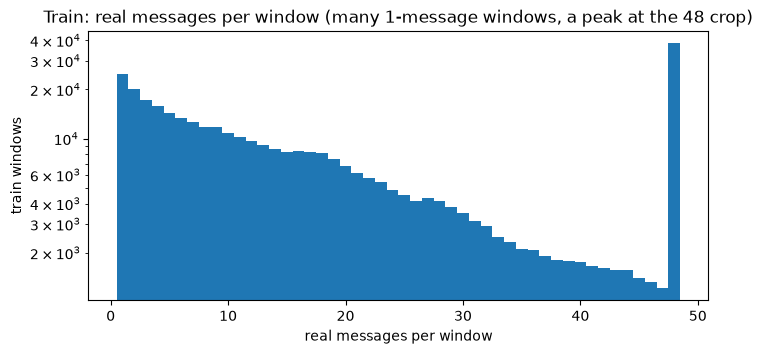

In [3]:
rows = []
for name, d in [("train", train), ("test", test)]:
    n = d.n_messages
    rows.append({"split": name, "min": n.min(), "median": np.median(n), "mean": round(n.mean(), 2), "max": n.max(),
                 "padding share": round(1 - d.mask.mean(), 3)})
display(pd.DataFrame(rows).set_index("split"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.n_messages, bins=np.arange(1, 50) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window"); ax.set_ylabel("train windows"); ax.set_yscale("log")
ax.set_title("Train: real messages per window (many 1-message windows, a peak at the 48 crop)")
plt.show()

Per-feature mean and standard deviation over **real** train rows (values are already normalised).

In [4]:
real = train.x[train.mask]  # (real rows, 13)
pd.DataFrame({"mean": real.mean(0), "std": real.std(0), "min": real.min(0), "max": real.max(0)}, index=FEATURES).round(3)

,mean,std,min,max
claimed_pos_x,-0.0,1.003,-19.377001,13.215000
claimed_pos_y,-0.0,1.005,-23.691000,20.629000
rx_pos_x,-0.0,0.999,-1.156000,2.326000
rx_pos_y,-0.0,0.994,-2.056000,2.353000
claimed_vel_x,-0.0,0.996,-3.545000,3.462000
claimed_vel_y,-0.0,0.997,-3.211000,3.048000
rx_vel_x,0.0,0.993,-2.527000,2.569000
rx_vel_y,-0.0,0.998,-2.325000,2.220000
claimed_acl_x,-0.0,0.995,-4.629000,4.629000
claimed_acl_y,-0.0,0.995,-3.545000,3.566000


One train window (the longest of the first windows): its 13 feature traces over the real rows; the rest is padding.

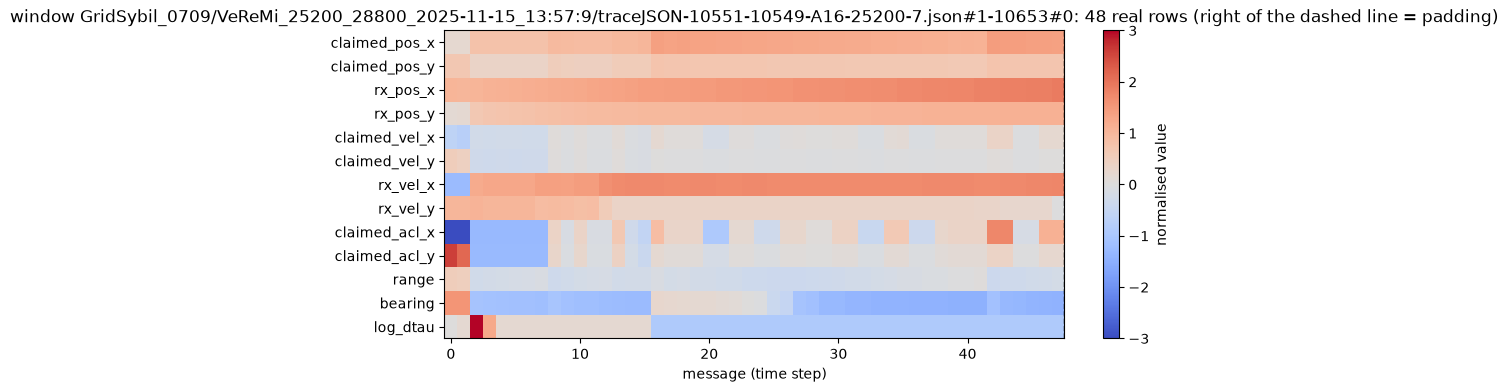

In [5]:
i = int(np.argmax(train.n_messages[:2000]))
n = train.n_messages[i]
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(train.x[i].T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
ax.axvline(n - 0.5, color="black", ls="--", lw=1)
ax.set_yticks(range(len(FEATURES)), FEATURES); ax.set_xlabel("message (time step)")
ax.set_title(f"window {train.ids[i]}: {n} real rows (right of the dashed line = padding)")
fig.colorbar(im, ax=ax, label="normalised value")
plt.show()

## 2. Model

Layers with their output shapes for one batch of 2 windows, and the trainable parameter count.

In [6]:
model = ConvAutoencoder(settings)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table = []
hooks = [mod.register_forward_hook(lambda mod, inp, out, name=name: table.append(
    (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))))
    for name, mod in model.named_modules() if isinstance(mod, (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear))]
model.eval()
with torch.no_grad():
    recon0, z0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]))
print(f"trainable parameters: {count_params(model):,}")

,layer,type,output (per window),params
0,encoder_conv.0,Conv1d,"(32, 48)",1376
1,encoder_conv.3,Conv1d,"(64, 24)",6208
2,encoder_conv.6,Conv1d,"(64, 12)",12352
3,to_z,Linear,"(16,)",12304
4,from_z,Linear,"(768,)",13056
5,decoder_conv.1,ConvTranspose1d,"(64, 24)",16448
6,decoder_conv.4,ConvTranspose1d,"(32, 48)",8224
7,decoder_conv.7,Conv1d,"(13, 48)",1261


reconstruction: (48, 13)  z: (16,)
trainable parameters: 71,741


## 3. Training record

What `task.autoencoder.train` wrote: the summary, the per-epoch history (train vs validation masked MSE, best epoch,
LR drops) and the first and last lines of `train.log`.

{
  "run_id": "seed0",
  "params": 71741,
  "best_epoch": 170,
  "best_val_loss": 0.13978534098286502,
  "epochs_run": 180,
  "stop_reason": "early_stopping",
  "lr_changes": [
    {
      "after_epoch": 91,
      "from": 0.001,
      "to": 0.0005
    },
    {
      "after_epoch": 109,
      "from": 0.0005,
      "to": 0.00025
    },
    {
      "after_epoch": 118,
      "from": 0.00025,
      "to": 0.000125
    },
    {
      "after_epoch": 128,
      "from": 0.000125,
      "to": 6.25e-05
    },
    {
      "after_epoch": 141,
      "from": 6.25e-05,
      "to": 3.125e-05
    },
    {
      "after_epoch": 153,
      "from": 3.125e-05,
      "to": 1.5625e-05
    },
    {
      "after_epoch": 162,
      "from": 1.5625e-05,
      "to": 7.8125e-06
    },
    {
      "after_epoch": 168,
      "from": 7.8125e-06,
      "to": 3.90625e-06
    },
    {
      "after_epoch": 176,
      "from": 3.90625e-06,
      "to": 1.953125e-06
    }
  ],
  "train_seconds": 911.9,
  "fit_windows": 320168,
  

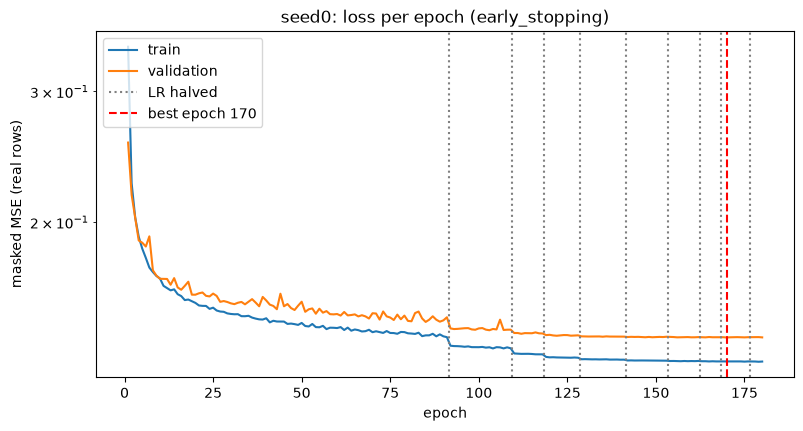

2026-10-27T23:44:15 train windows 355,382 (5s to load), shape (48, 13) + mask; fit 320,168 / val 35,214 windows (518 of 5,178 vehicles held out)
2026-10-27T23:44:15 padding share 0.633, real messages per window median 13
2026-10-27T23:44:15 ConvAutoencoder: 71,741 trainable parameters, input 14 x 48, z 16
2026-10-27T23:44:16 fit: 320,168 windows, val: 35,214 windows, batch 256, device mps
2026-10-27T23:44:22 epoch   1  train 0.34469  val 0.25600  lr 1.00e-03  6.0s *best
2026-10-27T23:44:27 epoch   2  train 0.22562  val 0.21764  lr 1.00e-03  5.0s *best
...
2026-10-27T23:59:17 epoch 178  train 0.12974  val 0.13989  lr 1.95e-06  5.0s (no improvement 8/10)
2026-10-27T23:59:23 epoch 179  train 0.12965  val 0.13996  lr 1.95e-06  5.0s (no improvement 9/10)
2026-10-27T23:59:28 epoch 180  train 0.12973  val 0.13984  lr 1.95e-06  5.0s (no improvement 10/10)
2026-10-27T23:59:28 early stopping: no improvement for 10 epochs; best epoch 170 val 0.13979
2026-10-27T23:59:28 done: {"run_id": "seed0", "

In [7]:
summary = json.loads((RUN / "summary.json").read_text())
print(json.dumps(summary, indent=2))
history = pd.read_json(RUN / "history.jsonl", lines=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history.epoch, history.train_loss, label="train")
ax.plot(history.epoch, history.val_loss, label="validation")
for k, c in enumerate(summary["lr_changes"]):
    ax.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", label="LR halved" if k == 0 else None)
ax.axvline(summary["best_epoch"], color="red", ls="--", label=f"best epoch {summary['best_epoch']}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("masked MSE (real rows)"); ax.legend()
ax.set_title(f"{RUN.name}: loss per epoch ({summary['stop_reason']})")
plt.show()
log = (RUN / "train.log").read_text().splitlines()
print("\n".join(log[:6] + ["..."] + log[-5:]))

## 4. Reconstruction

Load `best.pt` and rebuild the validation windows (the same vehicle split as training). A few long validation windows:
input vs reconstruction for three features. Then the mean reconstruction error per feature over validation.

validation windows 35,214; mean window error 0.1236 (run's best val loss, pooled over rows: 0.1398)


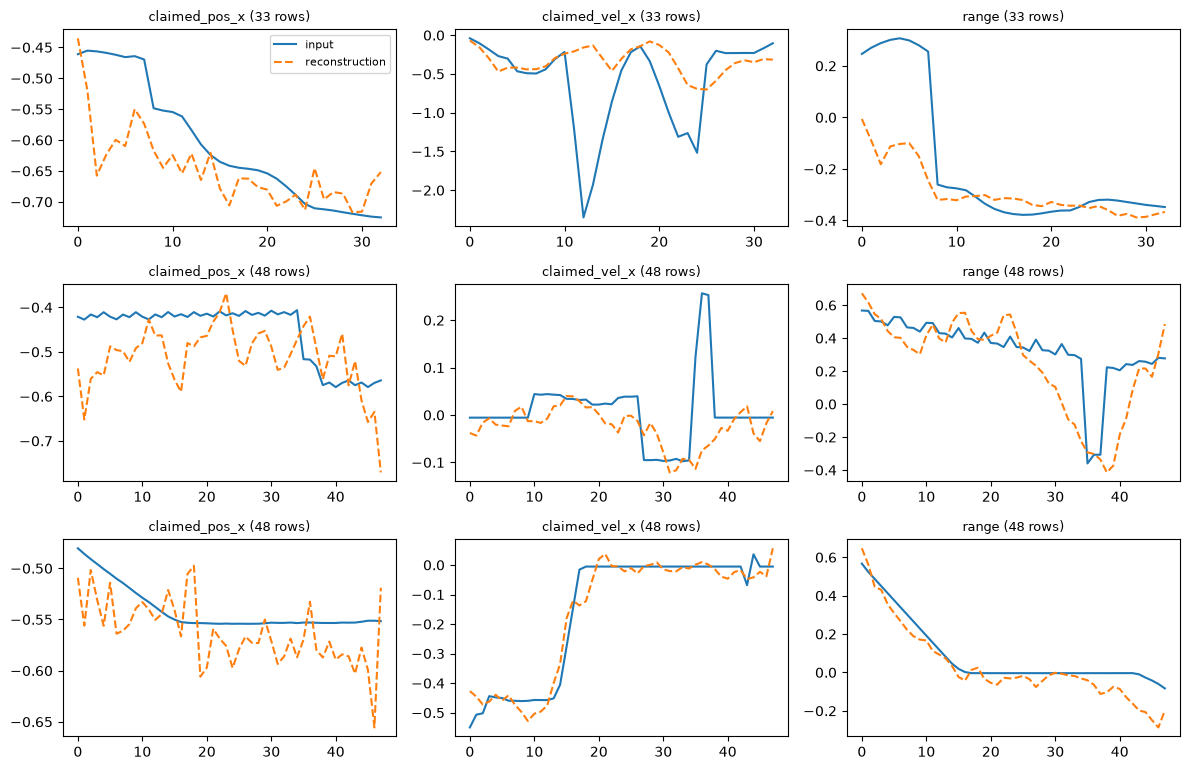

,validation MSE
claimed_acl_y,0.3709
claimed_acl_x,0.3503
log_dtau,0.2474
bearing,0.1499
rx_vel_x,0.1180
rx_vel_y,0.1074
claimed_vel_y,0.0705
claimed_vel_x,0.0683
range,0.0405
claimed_pos_y,0.0276


In [8]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
cfg = trainer.settings
_, val_rows = vehicle_split(train.vehicles, cfg.val_frac, cfg.seed)
val = train.take(val_rows)
val_out = trainer.score(val.x, val.mask, keep_recon=True)
print(f"validation windows {len(val):,}; mean window error {val_out['error'].mean():.4f} "
      f"(run's best val loss, pooled over rows: {summary['best_val_loss']:.4f})")

show = ["claimed_pos_x", "claimed_vel_x", "range"]
picks = np.flatnonzero(val.n_messages >= 30)[:3]
fig, axes = plt.subplots(len(picks), len(show), figsize=(12, 2.6 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    n = val.n_messages[i]
    for c, f in enumerate(show):
        j = FEATURES.index(f)
        axes[r, c].plot(val.x[i, :n, j], label="input")
        axes[r, c].plot(val_out["recon"][i, :n, j], "--", label="reconstruction")
        axes[r, c].set_title(f"{f} ({n} rows)", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

pd.Series(val_out["error_feature"].mean(0), index=FEATURES, name="validation MSE").sort_values(ascending=False).round(4).to_frame()

## 5. Test (T = 48 test split)

Reconstruction errors for every test window are computed **first**; labels are read only after that.

In [9]:
test_out = trainer.score(test.x, test.mask)
score = test_out["error"]
print(f"scored {len(score):,} test windows")
y = (test.info["label"].astype(int) == 16).astype(int)  # labels read here, after scoring; GridSybil = positive
print(f"benign {int((y == 0).sum()):,}, GridSybil {int(y.sum()):,}")

scored 40,469 test windows
benign 13,405, GridSybil 27,064


Error histograms by class, AUROC and PR-AUC with GridSybil as the positive class (PR-AUC chance level = GridSybil share).

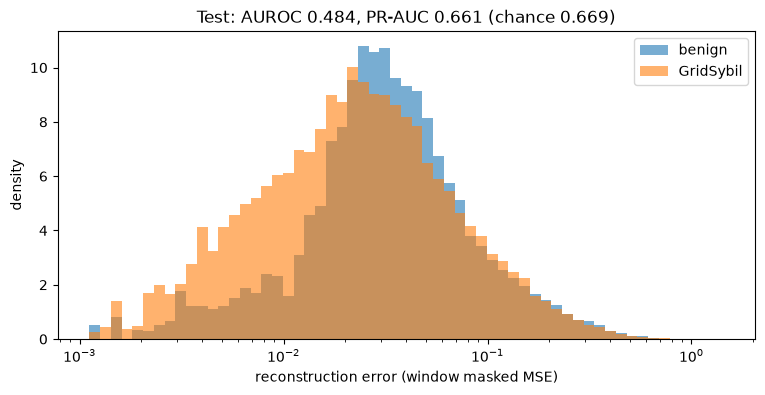

In [10]:
auroc, prauc = roc_auc_score(y, score), average_precision_score(y, score)
bins = np.logspace(np.log10(max(score.min(), 1e-5)), np.log10(score.max()), 60)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(score[y == 0], bins=bins, alpha=0.6, density=True, label="benign")
ax.hist(score[y == 1], bins=bins, alpha=0.6, density=True, label="GridSybil")
ax.set_xscale("log"); ax.set_xlabel("reconstruction error (window masked MSE)"); ax.set_ylabel("density"); ax.legend()
ax.set_title(f"Test: AUROC {auroc:.3f}, PR-AUC {prauc:.3f} (chance {y.mean():.3f})")
plt.show()

Threshold = 95th percentile of the **validation** errors (no labels): windows above it are called attacks.

In [11]:
theta = float(np.percentile(val_out["error"], 95))
pred = (score > theta).astype(int)
p, r, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f"threshold {theta:.4f}: precision {p:.3f}, recall {r:.3f}, F1 {f1:.3f}, benign FPR {fp / (fp + tn):.3f}")
pd.DataFrame([[tn, fp], [fn, tp]], index=["true benign", "true GridSybil"], columns=["pred benign", "pred GridSybil"])

threshold 0.3724: precision 0.654, recall 0.046, F1 0.087, benign FPR 0.049


,pred benign,pred GridSybil
true benign,12742,663
true GridSybil,25810,1254


Mean per-feature error, benign vs GridSybil, and the per-feature AUROC (which features carry the difference).

In [12]:
ef = test_out["error_feature"]
pd.DataFrame({
    "benign": ef[y == 0].mean(0),
    "GridSybil": ef[y == 1].mean(0),
    "AUROC": [roc_auc_score(y, ef[:, j]) for j in range(ef.shape[1])],
}, index=FEATURES).round(4).sort_values("AUROC", ascending=False)

,benign,GridSybil,AUROC
range,0.0174,0.0435,0.6495
claimed_pos_y,0.0116,0.0299,0.6226
log_dtau,0.1446,0.2859,0.6168
claimed_pos_x,0.0125,0.0294,0.5759
bearing,0.1130,0.1592,0.5455
rx_pos_y,0.0156,0.0197,0.5162
rx_pos_x,0.0142,0.0168,0.4983
rx_vel_y,0.1044,0.0963,0.4778
rx_vel_x,0.1167,0.1087,0.4711
claimed_acl_y,0.3741,0.3639,0.4648


Error by window length (real messages). Short windows have little to reconstruct; length alone is a known shortcut.

In [13]:
groups = pd.cut(test.n_messages, [0, 3, 16, 32, 48], labels=["<= 3", "4-16", "17-32", "33-48"])
rows = []
for g in groups.categories:
    s = np.asarray(groups == g)
    yy, ss = y[s], score[s]
    rows.append({"length": g, "windows": int(s.sum()), "GridSybil share": round(yy.mean(), 3),
                 "median error benign": np.median(ss[yy == 0]), "median error GridSybil": np.median(ss[yy == 1]),
                 "AUROC": roc_auc_score(yy, ss) if 0 < yy.sum() < len(yy) else np.nan,
                 "flagged at θ": round((ss > theta).mean(), 3)})
display(pd.DataFrame(rows).set_index("length").round(4))
print(f"length-only AUROC (fewer messages = more suspicious): {roc_auc_score(y, -test.n_messages):.3f}")

,windows,GridSybil share,median error benign,median error GridSybil,AUROC,flagged at θ
length,,,,,,
<= 3,6849,0.730,0.0440,0.0279,0.3782,0.008
4-16,16468,0.666,0.0936,0.0855,0.4734,0.054
17-32,9431,0.623,0.0690,0.0903,0.5538,0.055
33-48,7721,0.677,0.0777,0.0897,0.5369,0.060


length-only AUROC (fewer messages = more suspicious): 0.530


2-D PCA of the test latent z, coloured by class (analysis only; z was never trained to separate classes).

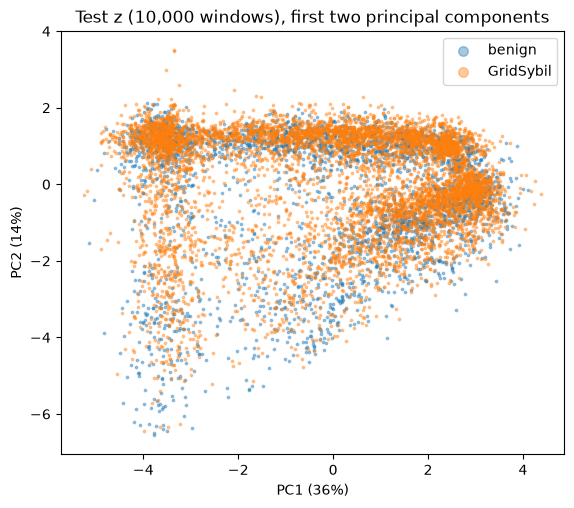

In [14]:
rng = np.random.default_rng(0)
sub = rng.choice(len(y), size=min(10000, len(y)), replace=False)
pca = PCA(2, random_state=0).fit(test_out["z"])
zz = pca.transform(test_out["z"][sub])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for cls, name in [(0, "benign"), (1, "GridSybil")]:
    s = y[sub] == cls
    ax.scatter(zz[s, 0], zz[s, 1], s=3, alpha=0.4, label=name)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=4); ax.set_title("Test z (10,000 windows), first two principal components")
plt.show()

The numbers the analysis below refers to.

In [15]:
results = {"run": RUN.name, "best_epoch": summary["best_epoch"], "best_val_loss": round(summary["best_val_loss"], 5),
           "test_auroc": round(auroc, 3), "test_pr_auc": round(prauc, 3), "gridsybil_share": round(y.mean(), 3),
           "threshold_p95_val": round(theta, 4), "precision": round(p, 3), "recall": round(r, 3), "f1": round(f1, 3),
           "benign_fpr": round(fp / (fp + tn), 3), "length_only_auroc": round(roc_auc_score(y, -test.n_messages), 3)}
results

{'run': 'seed0',
 'best_epoch': 170,
 'best_val_loss': 0.13979,
 'test_auroc': 0.484,
 'test_pr_auc': 0.661,
 'gridsybil_share': np.float64(0.669),
 'threshold_p95_val': 0.3724,
 'precision': 0.654,
 'recall': 0.046,
 'f1': 0.087,
 'benign_fpr': np.float64(0.049),
 'length_only_auroc': 0.53}

## 6. Overall analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals).

- **Training worked as a reconstruction model.** Validation masked MSE fell from 0.256 (epoch 1) to **0.140** (best,
  epoch 170); early stopping ended the run at epoch 180 after 9 LR halvings (1e-3 to 2e-6). Train and validation end
  close (0.130 vs 0.140), so there is little overfitting. Acceleration and log-Δτ are the hardest features to rebuild;
  positions the easiest.
- **Reconstruction error does not detect GridSybil here.** Test AUROC **0.484** (chance 0.5, below the length-only
  shortcut 0.530); PR-AUC **0.661** against a chance level of 0.669. At the label-free threshold (95th percentile of
  validation errors) benign FPR is 0.049 as designed, but recall is **0.046**, precision 0.654 (the GridSybil base
  rate) and F1 0.087.
- **Per feature the signal points both ways.** GridSybil windows are rebuilt *worse* on range, claimed position and
  log-Δτ (per-feature AUROC 0.58–0.65) but *better* on claimed velocity (0.27–0.28): the ghosts' claimed motion is
  simpler than real driving. In the mean error these cancel. Picking a signed feature score from this table would use
  test labels, so it is not done here.
- **Short windows:** for ≤ 3 messages AUROC is 0.378 (GridSybil reconstructs better); for 17–48 messages it is only
  0.54–0.55.
- **Why this is expected:** training treated every window as normal, and GridSybil is 64% of the train windows, so the
  autoencoder was never taught that GridSybil is abnormal; it learned to rebuild ghosts as well as (or better than)
  real cars. The PCA plot of z is shown for inspection only.
- **Context only, not a fair comparison:** the one-class autoencoder in `task/encoder` (T = 64, trained on benign
  windows only) reached AUROC 0.655; the training set and T both differ, so the gap cannot be attributed to one cause.